# Steam Game Thumbnail Generation with a GAN

Every Steam game has a header image: a 460 × 215 banner with a logo, a character and a colour mood that tries to make you click.
Can a neural network learn what a Steam thumbnail looks like, well enough to invent new ones? This notebook downloads thousands of
real headers, trains a **GAN** (two networks competing: one forges thumbnails, one detects forgeries; DCGAN architecture with the stabilising tricks of SN-GAN), and then asks honest
questions: how close are the fakes to real thumbnails (FID), did the network simply copy its training images, and what does its
"imagination space" look like?

**Objectives**
1. What do real Steam thumbnails look like, as data?
2. How does a GAN learn, and why is its training a balancing act?
3. How do the generator and discriminator turn noise into a 64 × 128 image and back into a verdict?
4. How do we know training works when there is no accuracy to watch?
5. How realistic are the generated thumbnails, measured with the Fréchet Inception Distance?
6. Did the GAN invent new images or memorise training ones?
7. What happens when we walk through the latent space between two fakes?

**Data** → [Kaggle dataset nikdavis/steam-store-games](https://www.kaggle.com/datasets/nikdavis/steam-store-games) · header image URLs in `steam_media_data.csv` · images downloaded from Steam's CDN (needs Internet on)

# [1/12] Setup

Set every knob once in the top cell → later cells only read them; downloaded images are cached in `WORK_DIR`

In [ ]:
"""Optional · Edit the settings, then run all cells. Explanations: README.md

[1/11] DATA_DIR: dataset folder (searched recursively for steam_media_data.csv if not found here)
    Default = '/kaggle/input/datasets/nikdavis/steam-store-games'
[2/11] WORK_DIR: folder for the image cache and exported figures
    Default = '/kaggle/working'
[3/11] N_IMAGES: thumbnails downloaded (training set + held-out set)
    Default = 12000
[4/11] N_HOLDOUT: real thumbnails kept out of training, used for FID and the memorisation check
    Default = 2000
[5/11] IMG_H / IMG_W: training size, keeps the 2 : 1 banner shape
    Default = 64 / 128
[6/11] LATENT_DIM: length of the random noise vector z
    Default = 128
[7/11] EPOCHS / BATCH_SIZE: training length
    Default = 100 / 128
[8/11] LR_G / LR_D: learning rates of generator and discriminator (two time-scale update rule)
    Default = 0.0001 / 0.0004
[9/11] DOWNLOAD_WORKERS: parallel downloads
    Default = 32
[10/11] SEED: random seed
    Default = 42
[11/11] SAVE_FIGURES: write every chart to WORK_DIR/assets
    Default = False
    For example:
        SAVE_FIGURES = True
"""
DATA_DIR         = '/kaggle/input/datasets/nikdavis/steam-store-games'
WORK_DIR         = '/kaggle/working'
N_IMAGES         = 12000
N_HOLDOUT        = 2000
IMG_H, IMG_W     = 64, 128
LATENT_DIM       = 128
EPOCHS           = 100
BATCH_SIZE       = 128
LR_G             = 0.0001
LR_D             = 0.0004
DOWNLOAD_WORKERS = 32
SEED             = 42
SAVE_FIGURES     = False

ADAM_BETAS       = (0.0, 0.9)             # usual for hinge-loss GANs with spectral normalisation
EMA_DECAY        = 0.999                  # generator weights averaged over training steps (smoother images)
SNAPSHOT_EPOCHS  = (1, 5, 10, 25, 50, 75, 100)
N_GRID           = 32                     # images per grid
N_NOISE_FID      = 2000                   # random-noise images used as the worst-case FID reference
INTERP_STEPS     = 9
PAD              = 32
PALETTE          = {'main': 'black', 'flag': 'red', 'soft': 'grey'}

In [ ]:
import io
import time
import warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from IPython.display import display
from PIL import Image
from scipy import linalg

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils import spectral_norm
from torchvision.models import Inception_V3_Weights, inception_v3

warnings.filterwarnings('ignore')
sns.set_style('darkgrid')
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
ASSETS = Path(WORK_DIR) / 'assets'
CACHE = Path(WORK_DIR) / f'steam_thumbnails_{N_IMAGES}_{IMG_H}x{IMG_W}.npz'
Path(WORK_DIR).mkdir(parents=True, exist_ok=True)
if SAVE_FIGURES:
    ASSETS.mkdir(parents=True, exist_ok=True)
if DEVICE.type == 'cpu':
    print('(!) No GPU found -> training will be slow. Kaggle: Settings -> Accelerator -> GPU')

In [ ]:
def show_block(title, items):
    print(f'{title}:')
    for key, value in items.items():
        print(f'    {key:<{PAD}}{value}')


def save(fig, name):
    if SAVE_FIGURES:
        fig.savefig(ASSETS / f'{name}.png', bbox_inches='tight', dpi=110)


def find_data_dir(default, root='/kaggle/input'):
    """Folder that holds steam_media_data.csv and steam.csv. Tries `default`, then searches `root`."""
    candidates = [Path(default)]
    if Path(root).exists():
        candidates += sorted(p.parent for p in Path(root).rglob('steam_media_data.csv'))
    for folder in candidates:
        if (folder / 'steam_media_data.csv').is_file() and (folder / 'steam.csv').is_file():
            return folder
    mounted = sorted(str(p) for p in Path(root).glob('*/*'))[:20] if Path(root).exists() else []
    raise FileNotFoundError(f'(!) No steam_media_data.csv under {default} or {root}.\n'
                            f'    Add Input -> Datasets -> nikdavis/steam-store-games\n'
                            f'    Mounted now: {mounted or "nothing"}')


def to_display(batch):
    """Tensor in [-1, 1], shape (n, 3, H, W) -> uint8 numpy (n, H, W, 3)."""
    x = ((batch.detach().cpu().clamp(-1, 1) + 1) * 127.5).round().byte()
    return x.permute(0, 2, 3, 1).numpy()


def grid(images, ncols=8):
    """uint8 (n, H, W, 3) -> one big image."""
    n, h, w, c = images.shape
    nrows = int(np.ceil(n / ncols))
    canvas = np.full((nrows * (h + 2), ncols * (w + 2), c), 255, dtype=np.uint8)
    for i, im in enumerate(images):
        r, k = divmod(i, ncols)
        canvas[r * (h + 2): r * (h + 2) + h, k * (w + 2): k * (w + 2) + w] = im
    return canvas

# [2/12] Data and download

Sample games, download their header images once, crop them to 2 : 1 and shrink to 64 × 128 → a cached array of real thumbnails

In [ ]:
data_dir = find_data_dir(DATA_DIR)
media = pd.read_csv(data_dir / 'steam_media_data.csv').rename(columns={'steam_appid': 'appid'})
store = pd.read_csv(data_dir / 'steam.csv', usecols=['appid', 'name', 'genres', 'positive_ratings', 'negative_ratings'])
catalogue = store.merge(media[['appid', 'header_image']], on='appid').dropna(subset=['header_image'])
sample = catalogue.sample(n=min(N_IMAGES, len(catalogue)), random_state=SEED).reset_index(drop=True)
show_block('Inputs', {'data folder': data_dir, 'games with a header image': len(catalogue), 'sampled': len(sample),
                      'example URL': sample.loc[0, 'header_image'].split('?')[0]})

In [ ]:
def fetch(url, retries=3):
    """Download one header, centre-crop to 2:1, resize to IMG_W x IMG_H. Returns uint8 array or None."""
    for attempt in range(retries):
        try:
            r = requests.get(url, timeout=15)
            r.raise_for_status()
            im = Image.open(io.BytesIO(r.content)).convert('RGB')
            w, h = im.size
            target_w = min(w, 2 * h)
            left = (w - target_w) // 2
            im = im.crop((left, 0, left + target_w, target_w // 2)).resize((IMG_W, IMG_H), Image.LANCZOS)
            return np.asarray(im, dtype=np.uint8)
        except Exception:
            time.sleep(1 + attempt)
    return None


start = time.time()
if CACHE.exists():
    cached = np.load(CACHE, allow_pickle=True)
    images, kept_appids = cached['images'], cached['appids']
    source = 'cache'
else:
    with ThreadPoolExecutor(DOWNLOAD_WORKERS) as pool:
        results = list(pool.map(fetch, sample['header_image']))
    ok = np.array([r is not None for r in results])
    if ok.sum() == 0:
        raise RuntimeError('(!) No image could be downloaded. Kaggle: Settings -> Internet -> On')
    images = np.stack([r for r in results if r is not None])
    kept_appids = sample.loc[ok, 'appid'].to_numpy()
    np.savez_compressed(CACHE, images=images, appids=kept_appids)
    source = 'download'
meta = sample.set_index('appid').loc[kept_appids].reset_index()

In [ ]:
show_block('Outputs', {'source': source, 'images': images.shape, 'failed downloads': len(sample) - len(images),
                       'seconds': round(time.time() - start, 1), 'cache file': CACHE.name,
                       'cache size (MB)': round(CACHE.stat().st_size / 2 ** 20, 1)})

**Question:** How much data does the GAN get, and in what form?

**Answer:** 11,999 of 12,000 sampled headers downloaded (one failed) in about 4 minutes and are cached as a 214 MB array, so a re-run
skips the download. Each 460 × 215 banner is centre-cropped to 2 : 1 and shrunk to 64 × 128 pixels, then scaled to [−1, 1] to match the
generator's tanh output. 9,999 thumbnails train the GAN; 2,000 are held out and only used for evaluation.

In [ ]:
perm = rng.permutation(len(images))
holdout_idx, train_idx = perm[:N_HOLDOUT], perm[N_HOLDOUT:]
X_train = torch.from_numpy(images[train_idx]).permute(0, 3, 1, 2).float().div(127.5).sub(1)     # [-1, 1]
X_hold = torch.from_numpy(images[holdout_idx]).permute(0, 3, 1, 2).float().div(127.5).sub(1)
show_block('Split', {'training thumbnails': len(X_train), 'held-out thumbnails': len(X_hold),
                     'tensor shape': tuple(X_train.shape), 'pixel range': (float(X_train.min()), float(X_train.max()))})

# [3/12] Real thumbnails

Look at a random grid, the average thumbnail and the colour distribution → what the generator has to imitate

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(20, 6), gridspec_kw={'width_ratios': [3, 1]})
axes[0].imshow(grid(images[train_idx[:N_GRID]]))
axes[0].set(title=f'{N_GRID} real Steam thumbnails (64 x 128)', xticks=[], yticks=[])
axes[1].imshow(images[train_idx].mean(axis=0).astype(np.uint8))
axes[1].set(title='Average of all training thumbnails', xticks=[], yticks=[])
fig.tight_layout()
save(fig, '01_real_thumbnails')
plt.show()

In [ ]:
channel_mean = images[train_idx].mean(axis=(0, 1, 2), dtype=np.float64)
brightness = images[train_idx].mean(axis=(1, 2, 3), dtype=np.float64)
show_block('Colour statistics', {'mean R / G / B': tuple(float(v) for v in channel_mean.round(1)),
                                 'mean brightness (0-255)': round(float(brightness.mean()), 1),
                                 'darkest 10 % of thumbnails below': round(float(np.percentile(brightness, 10)), 1),
                                 'brightest 10 % above': round(float(np.percentile(brightness, 90)), 1)})

**Question:** What makes thumbnails hard to generate?

**Answer:** thumbnails are among the hardest images to imitate:
- **Text** → most banners carry a stylised game logo; letters need sharp, exact shapes that a small GAN at 64 × 128 cannot spell
- **Variety** → pixel art, 3-D renders, anime, photos and plain logos share one dataset; there is no common object like a face
- **Colour** → average RGB (104.9, 97.9, 93.6) and brightness 98.8 out of 255: mostly dark, warm banners, with the darkest 10 % below 42
  and the brightest 10 % above 162

The average of all thumbnails is a dark blur with a slightly brighter centre: the title usually sits in the middle.

# [4/12] How a GAN learns

Two networks play a game: the generator $G$ forges thumbnails from noise, the discriminator $D$ tells real from fake → each improves by beating the other

**Question:** What exactly do the two networks optimise?

$$\min_G \max_D \; V(D, G) = \mathbb{E}_{x \sim p_{data}}\left[\log D(x)\right] + \mathbb{E}_{z \sim \mathcal{N}(0, I)}\left[\log\left(1 - D(G(z))\right)\right]$$
- $x$ → a real thumbnail, $z$ → a vector of 128 random numbers, $G(z)$ → a forged thumbnail, $D(\cdot)$ → probability "real"
- **Discriminator** → wants $D(x) \to 1$ and $D(G(z)) \to 0$
- **Equilibrium** → if $G$ reproduced the real distribution perfectly, the best $D$ could do is guess: $D = 0.5$ everywhere
- **Hinge loss (used here)** → a more stable version of the same game, where $D$ outputs a score $s$ instead of a probability:

$$L_D = \mathbb{E}\left[\max(0, 1 - s(x))\right] + \mathbb{E}\left[\max(0, 1 + s(G(z)))\right] \qquad L_G = -\mathbb{E}\left[s(G(z))\right]$$
  $D$ is only pushed until real scores exceed +1 and fake scores fall below −1, so it cannot become arbitrarily confident
- **Stabilisers** → *spectral normalisation* caps how sharply $D$ can react to small input changes (Miyato et al. 2018); *two learning rates* (TTUR):
  $D$ learns 4× faster than $G$; *upsample + convolution* in $G$ instead of transposed convolutions avoids checkerboard artefacts;
  an *exponential moving average* of $G$'s weights gives smoother samples
- My first attempt used the plain DCGAN recipe (BCE loss, transposed convolutions): $D$ won early, and the images showed checkerboard patterns and FID 227
- Analogy → a counterfeiter and a bank teller: the teller's mistakes teach the counterfeiter, and better fakes make the teller sharper

**Answer:** the discriminator learns to tell real from fake, and the generator learns only through the discriminator's feedback — it
never sees a real image directly. Training is a balancing act: if $D$ wins completely, $G$ receives no useful gradient; if $D$ is too weak,
its feedback is meaningless. The hinge loss, spectral normalisation and the two learning rates keep that contest going.

# [5/12] Architecture

Build the generator (noise → 4 × 8 → … → 64 × 128 image, upsample + convolution) and the spectral-normalised discriminator → count their parameters

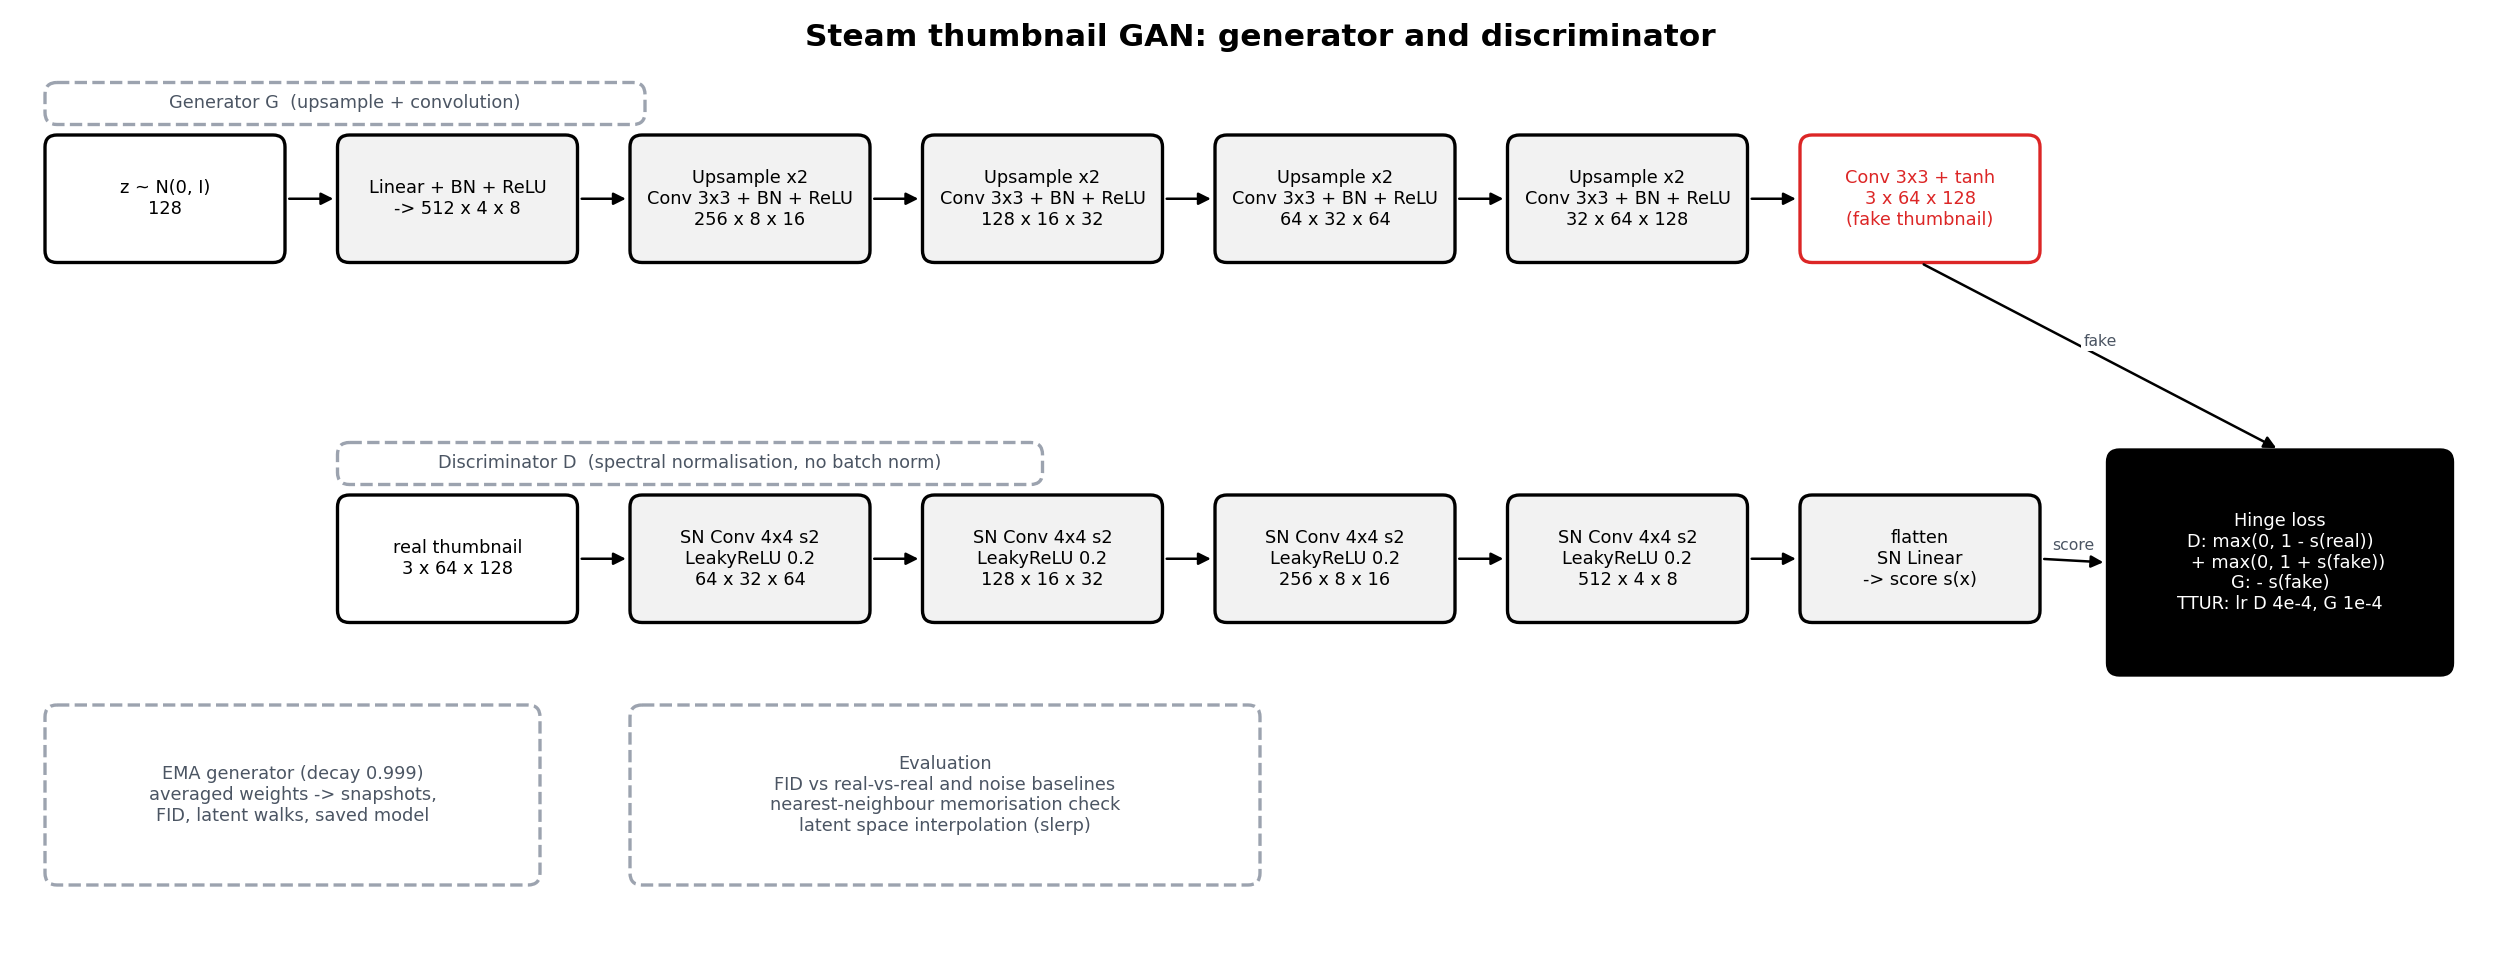

In [ ]:
class Generator(nn.Module):
    """z (128) -> dense 512 x 4 x 8 -> 4 x [upsample x2 + conv 3x3 + BN + ReLU] -> conv 3x3 -> tanh -> 3 x 64 x 128"""
    def __init__(self, z=LATENT_DIM, f=64):
        super().__init__()
        self.f = f
        self.fc = nn.Sequential(nn.Linear(z, f * 8 * 4 * 8, bias=False), nn.BatchNorm1d(f * 8 * 4 * 8), nn.ReLU(True))
        def up(cin, cout):
            return [nn.Upsample(scale_factor=2, mode='nearest'), nn.Conv2d(cin, cout, 3, 1, 1, bias=False),
                    nn.BatchNorm2d(cout), nn.ReLU(True)]
        self.net = nn.Sequential(*up(f * 8, f * 4),          # 8 x 16
                                 *up(f * 4, f * 2),          # 16 x 32
                                 *up(f * 2, f),              # 32 x 64
                                 *up(f, f // 2),             # 64 x 128
                                 nn.Conv2d(f // 2, 3, 3, 1, 1), nn.Tanh())

    def forward(self, z):
        return self.net(self.fc(z).view(z.size(0), self.f * 8, 4, 8))


class Discriminator(nn.Module):
    """3 x 64 x 128 -> 4 x [spectral-norm conv 4x4 stride 2 + LeakyReLU] -> 512 x 4 x 8 -> spectral-norm linear -> score"""
    def __init__(self, f=64):
        super().__init__()
        def down(cin, cout):
            return [spectral_norm(nn.Conv2d(cin, cout, 4, 2, 1)), nn.LeakyReLU(0.2, True)]
        self.net = nn.Sequential(*down(3, f),                # 32 x 64
                                 *down(f, f * 2),            # 16 x 32
                                 *down(f * 2, f * 4),        # 8 x 16
                                 *down(f * 4, f * 8))        # 4 x 8
        self.out = spectral_norm(nn.Linear(f * 8 * 4 * 8, 1))

    def forward(self, x):
        return self.out(self.net(x).flatten(1)).view(-1)


G, D = Generator().to(DEVICE), Discriminator().to(DEVICE)
G_ema = Generator().to(DEVICE)
G_ema.load_state_dict(G.state_dict())
G_ema.eval()
with torch.no_grad():
    shape_g = tuple(G(torch.randn(2, LATENT_DIM, device=DEVICE)).shape)
    shape_d = tuple(D(torch.randn(2, 3, IMG_H, IMG_W, device=DEVICE)).shape)

In [ ]:
show_block('Networks', {'device': DEVICE, 'generator parameters': f'{sum(p.numel() for p in G.parameters()):,}',
                        'discriminator parameters': f'{sum(p.numel() for p in D.parameters()):,}',
                        'G: z (2, 128) ->': shape_g, 'D: image (2, 3, 64, 128) ->': shape_d})

# [6/12] Training

Alternate one discriminator step and one generator step per batch for 100 epochs → keep the losses, $D$'s scores and snapshots of the averaged generator on a fixed noise batch

In [ ]:
opt_d = torch.optim.Adam(D.parameters(), lr=LR_D, betas=ADAM_BETAS)
opt_g = torch.optim.Adam(G.parameters(), lr=LR_G, betas=ADAM_BETAS)
fixed_z = torch.randn(N_GRID, LATENT_DIM, device=DEVICE)
loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X_train), batch_size=BATCH_SIZE, shuffle=True,
                                     drop_last=True, generator=torch.Generator().manual_seed(SEED))
history, snapshots = [], {}
start = time.time()
for epoch in range(1, EPOCHS + 1):
    G.train(); D.train()
    sums = np.zeros(4)
    for (real,) in loader:
        real = real.to(DEVICE, non_blocking=True)
        b = real.size(0)
        # --- discriminator (hinge): push real scores above +1 and fake scores below -1
        fake = G(torch.randn(b, LATENT_DIM, device=DEVICE))
        s_real, s_fake = D(real), D(fake.detach())
        loss_d = F.relu(1 - s_real).mean() + F.relu(1 + s_fake).mean()
        opt_d.zero_grad(set_to_none=True); loss_d.backward(); opt_d.step()
        # --- generator: raise the discriminator's score of fakes
        loss_g = -D(fake).mean()
        opt_g.zero_grad(set_to_none=True); loss_g.backward(); opt_g.step()
        # --- exponential moving average of the generator weights
        with torch.no_grad():
            for p_ema, p in zip(G_ema.parameters(), G.parameters()):
                p_ema.lerp_(p, 1 - EMA_DECAY)
            for b_ema, b_ in zip(G_ema.buffers(), G.buffers()):
                b_ema.copy_(b_)
        sums += [loss_d.item(), loss_g.item(), s_real.mean().item(), s_fake.mean().item()]
    n = len(loader)
    history.append({'epoch': epoch, 'loss D': sums[0] / n, 'loss G': sums[1] / n, 'score real': sums[2] / n, 'score fake': sums[3] / n})
    if epoch in SNAPSHOT_EPOCHS:
        with torch.no_grad():
            snapshots[epoch] = to_display(G_ema(fixed_z))
    if epoch == 1 or epoch % 10 == 0:
        h = history[-1]
        print(f"[{epoch}/{EPOCHS}] loss D {h['loss D']:.3f} | loss G {h['loss G']:.3f} | score real {h['score real']:.2f} | "
              f"score fake {h['score fake']:.2f} | {time.time() - start:.0f} s")
history = pd.DataFrame(history).set_index('epoch')
train_seconds = time.time() - start
G = G_ema                                      # every later cell uses the averaged generator
torch.save({'state_dict': G_ema.state_dict(), 'latent_dim': LATENT_DIM, 'img_h': IMG_H, 'img_w': IMG_W},
           Path(WORK_DIR) / 'generator_ema.pt')

In [ ]:
show_block('Training', {'epochs': EPOCHS, 'batches per epoch': len(loader), 'seconds': round(train_seconds, 1),
                        'final score real / fake': (round(history['score real'].iloc[-1], 2), round(history['score fake'].iloc[-1], 2)),
                        'saved generator': 'generator_ema.pt'})

# [7/12] Training curves

Read the losses and $D$'s average verdicts per epoch → in a GAN, falling loss is **not** the goal; balance is

**Question:** How do we know a GAN is training well when there is no accuracy?

- **Losses** → $D$'s hinge loss → 0 would mean $D$ separates real and fake perfectly and $G$ gets no useful signal; a loss that stays near 1-2 means a contest
- **Scores** → the average score of real and fake images; a gap that stays moderate (instead of growing forever) means neither network wins outright
- **Mode collapse** → $G$ finds a few images that fool $D$ and produces only those: visible as near-identical images in a grid

**Answer:** training stays balanced for all 100 epochs:
- $D$'s hinge loss stays between 1.37 and 1.51 (a perfect discriminator would reach 0)
- real thumbnails score about +0.2 to +0.3 and fakes about −0.4 to −0.5: $D$ always tells them apart a little, but the gap does not grow,
  so neither network takes over
- no mode collapse: the 32 samples in section 8 are all different

My first attempt (BCE loss, transposed convolutions) behaved differently: $D$ rated real images 0.78 and fakes 0.12, winning from the start.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].plot(history.index, history['loss D'], color=PALETTE['main'], label='discriminator')
axes[0].plot(history.index, history['loss G'], color=PALETTE['flag'], label='generator')
axes[0].set(title='Loss per epoch', xlabel='epoch')
axes[0].legend()
axes[1].plot(history.index, history['score real'], color=PALETTE['main'], label='real images')
axes[1].plot(history.index, history['score fake'], color=PALETTE['flag'], label='generated images')
axes[1].axhline(0, color=PALETTE['soft'], ls='--', lw=1)
axes[1].set(title="Discriminator's average score", xlabel='epoch')
axes[1].legend()
fig.tight_layout()
save(fig, '02_training_curves')
plt.show()

In [ ]:
display(history.iloc[[0, 4, 9, 24, 49, 74, -1]].round(3))

# [8/12] What the generator learned, epoch by epoch

Show the same 8 noise vectors at each snapshot → colour and layout first, then shapes and logo-like text blocks

In [ ]:
fig, axes = plt.subplots(len(snapshots), 1, figsize=(18, 2.3 * len(snapshots)))
for ax, (ep, ims) in zip(axes, snapshots.items()):
    ax.imshow(grid(ims[:8], ncols=8))
    ax.set(xticks=[], yticks=[])
    ax.set_ylabel(f'epoch {ep}', rotation=0, ha='right', va='center', fontsize=12)
fig.tight_layout()
save(fig, '03_progress')
plt.show()

In [ ]:
fig, ax = plt.subplots(figsize=(20, 6))
ax.imshow(grid(snapshots[max(snapshots)]))
ax.set(title=f'{N_GRID} generated thumbnails after {EPOCHS} epochs', xticks=[], yticks=[])
save(fig, '04_generated')
plt.show()

**Question:** What did the generator learn, and in what order?

**Answer:** the averaged generator first produces dark, nearly uniform noise (epochs 1–10: the moving average still remembers the random
start), then colour regions and a horizon (epoch 25), and from epoch 50 recognisable thumbnail **layouts**: a title-like block of light
"letters" across the middle, a sky or dark background, and character-like shapes on one side. By epoch 100 the shapes are sharper and the
colour schemes vary (fire orange, sky blue, night black, neon red). The "text" looks like text from a distance but cannot be read, and no
checkerboard pattern remains.

# [9/12] How realistic? Fréchet Inception Distance

Compare the generated and real thumbnails through the eyes of an ImageNet-trained Inception network → one number, lower is better

**Question:** How do we score realism without asking humans?

$$\text{FID} = \lVert \mu_r - \mu_g \rVert^2 + \text{Tr}\left(\Sigma_r + \Sigma_g - 2\,(\Sigma_r \Sigma_g)^{1/2}\right)$$
- each image → its 2,048-number Inception-v3 feature vector (shapes, textures, objects the network learned on ImageNet)
- $\mu, \Sigma$ → mean and covariance of those features for real ($r$) and generated ($g$) images: FID is the distance between two Gaussians
- **References** → real vs real (two different sets of real thumbnails: the best possible score for this sample size) and random noise vs real (the worst)
- (!) FID depends on sample size and image size; compare numbers only within this notebook, not with published 256 × 256 results
- Analogy → comparing two bags of photos by their overall statistics (how many faces, how much text, which colours) instead of photo by photo

**Answer:** FID **101.5**, far better than random noise (379.6) but far from real thumbnails (25.8 between two real samples).
My first, plain DCGAN scored 226.6, so the stabilising changes more than halved the distance. The fakes capture the colours, layouts and
overall "look" of Steam banners, but not their objects and readable text.

In [ ]:
weights = Inception_V3_Weights.DEFAULT
inception = inception_v3(weights=weights, progress=False, aux_logits=True).to(DEVICE).eval()
inception.fc = nn.Identity()
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)


@torch.no_grad()
def inception_features(x, batch=100):
    feats = []
    for i in range(0, len(x), batch):
        b = x[i:i + batch].to(DEVICE)
        b = F.interpolate((b + 1) / 2, size=(299, 299), mode='bilinear', align_corners=False)
        feats.append(inception((b - MEAN) / STD).cpu().numpy().astype(np.float64))
    return np.concatenate(feats)


def fid(f1, f2):
    mu1, mu2 = f1.mean(0), f2.mean(0)
    s1, s2 = np.cov(f1, rowvar=False), np.cov(f2, rowvar=False)
    covmean, _ = linalg.sqrtm(s1 @ s2, disp=False)
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * covmean.real))


n_fid = len(X_hold)
with torch.no_grad():
    gen_imgs = torch.cat([G(torch.randn(500, LATENT_DIM, device=DEVICE)).cpu() for _ in range(int(np.ceil(n_fid / 500)))])[:n_fid]
noise_imgs = torch.rand(N_NOISE_FID, 3, IMG_H, IMG_W) * 2 - 1
feat_hold = inception_features(X_hold)
feat_train = inception_features(X_train[torch.from_numpy(rng.choice(len(X_train), n_fid, replace=False))])
feat_gen = inception_features(gen_imgs)
feat_noise = inception_features(noise_imgs)
fid_table = pd.Series({'real (train sample) vs real (held-out)': fid(feat_train, feat_hold),
                       'generated vs real (held-out)': fid(feat_gen, feat_hold),
                       'random noise vs real (held-out)': fid(feat_noise, feat_hold)}, name='FID').round(1)

In [ ]:
display(fid_table.to_frame())

# [10/12] Did it copy? Memorisation check

For each generated thumbnail find the most similar **training** thumbnail in Inception feature space → compare with how close held-out real thumbnails get

**Question:** Are the fakes new, or near-copies of training images?

$$\text{sim}(a, b) = \frac{\phi(a) \cdot \phi(b)}{\lVert \phi(a)\rVert\,\lVert \phi(b)\rVert}$$
- $\phi$ → Inception features; for every generated image take its **nearest** training image (highest similarity)
- **Reference** → do the same for held-out real thumbnails, which the GAN never saw: if fakes sit much closer to the training set than unseen real images do, the GAN memorised
- Analogy → checking an essay for plagiarism by finding the most similar text in the library, and comparing with how similar honest essays usually are

**Answer:** the GAN did **not** copy its training images. The nearest training thumbnail of a generated image has a cosine similarity of
0.774 on average (maximum 0.876), while unseen **real** thumbnails get closer to the training set (0.789 on average). The closest pairs
share a colour scheme and layout (a green farm scene, a dark logo on brown) but are different pictures.
(The held-out maximum of 1.000 comes from 5 groups of identical headers in the catalogue, such as re-releases of the same game.)

In [ ]:
train_ref = rng.choice(len(X_train), min(6000, len(X_train)), replace=False)
feat_ref = inception_features(X_train[torch.from_numpy(train_ref)])
ref_n = feat_ref / np.linalg.norm(feat_ref, axis=1, keepdims=True)


def nearest(feats):
    s = (feats / np.linalg.norm(feats, axis=1, keepdims=True)) @ ref_n.T
    return s.max(axis=1), s.argmax(axis=1)


sim_gen, nn_gen = nearest(feat_gen)
sim_hold, _ = nearest(feat_hold)
memo = pd.DataFrame({'generated': pd.Series(sim_gen).describe(), 'held-out real': pd.Series(sim_hold).describe()})

closest = np.argsort(-sim_gen)[:6]
fig, axes = plt.subplots(2, 6, figsize=(20, 4))
for k, g in enumerate(closest):
    axes[0, k].imshow(to_display(gen_imgs[g:g + 1])[0])
    axes[0, k].set_title(f'generated, sim {sim_gen[g]:.2f}', fontsize=9)
    axes[1, k].imshow(to_display(X_train[train_ref[nn_gen[g]]:train_ref[nn_gen[g]] + 1])[0])
    axes[1, k].set_title('nearest training image', fontsize=9)
for ax in axes.ravel():
    ax.set(xticks=[], yticks=[])
fig.suptitle('The 6 generated thumbnails closest to a training image', fontsize=13)
fig.tight_layout()
save(fig, '05_nearest_neighbours')
plt.show()

In [ ]:
display(memo.loc[['mean', '50%', 'max']].round(3))

# [11/12] Walking through the latent space

Move in a straight line (spherical interpolation) between two random noise vectors → a smooth morph means the GAN learned a continuous space, not a lookup table

**Question:** What happens between two generated thumbnails?

$$\text{slerp}(z_0, z_1; t) = \frac{\sin((1 - t)\,\Omega)}{\sin \Omega}\, z_0 + \frac{\sin(t\,\Omega)}{\sin \Omega}\, z_1, \qquad \cos \Omega = \frac{z_0 \cdot z_1}{\lVert z_0\rVert \lVert z_1\rVert}$$
- spherical rather than straight-line interpolation keeps $z$ at the typical length of Gaussian noise, where the generator was trained
- Analogy → a dimmer switch between two scenes instead of a cut

**Answer:** every walk changes **gradually**: backgrounds shift from sky to night, title blocks grow, move and change colour, shapes melt
into one another, with no sudden jumps. The generator has learned a continuous space of thumbnail styles rather than a list of stored images,
which is also why the app can make endless new thumbnails from a seed.

In [ ]:
def slerp(z0, z1, t):
    omega = torch.acos((z0 / z0.norm()) @ (z1 / z1.norm())).clamp(min=1e-6)
    return (torch.sin((1 - t) * omega) * z0 + torch.sin(t * omega) * z1) / torch.sin(omega)


rows = []
gen_z = torch.Generator(device='cpu').manual_seed(SEED + 1)
for _ in range(4):
    z0, z1 = torch.randn(LATENT_DIM, generator=gen_z), torch.randn(LATENT_DIM, generator=gen_z)
    zs = torch.stack([slerp(z0, z1, t) for t in torch.linspace(0, 1, INTERP_STEPS)]).to(DEVICE)
    with torch.no_grad():
        rows.append(to_display(G(zs)))
fig, ax = plt.subplots(figsize=(20, 5.5))
ax.imshow(grid(np.concatenate(rows), ncols=INTERP_STEPS))
ax.set(title='Latent space walks: each row morphs from one generated thumbnail to another', xticks=[], yticks=[])
save(fig, '06_latent_walk')
plt.show()

# [12/12] Summary

**Answer:**
- **Data** → 11,999 real Steam headers at 64 × 128, 2,000 held out for evaluation
- **Model** → DCGAN-style generator (upsample + convolution, 3.7 M parameters) vs spectral-normalised discriminator (2.8 M), hinge loss,
  two learning rates, averaged generator weights; 100 epochs in about 18 minutes on one RTX 5060
- **Quality** → FID 101.5 (real vs real 25.8, noise 379.6); the plain DCGAN baseline scored 226.6
- **Honesty check** → generated images sit no closer to the training set than unseen real ones (similarity 0.774 vs 0.789): no copying
- **What it learned** → banner layouts, colour moods and title-like blocks; not readable text or detailed characters
- **Next steps** → larger images with a progressive or StyleGAN-type model; conditioning on genre or cluster (from the recommender notebook)
  to generate "a horror thumbnail" or "a farming thumbnail"; more data (all 27,000 headers)